## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [2]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sherlock Chen

**Date:** 10/20/2026

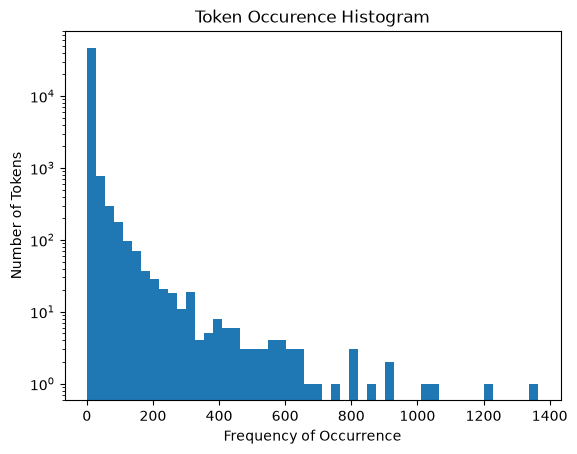

R^2 Test: 0.6571173475409766
R^2 Train: 0.7677733084118992
Top influential words: aging                0.996514
helvetica,           0.892177
localized            0.787934
background-image:    0.780070
thermal              0.671019
dtype: float64


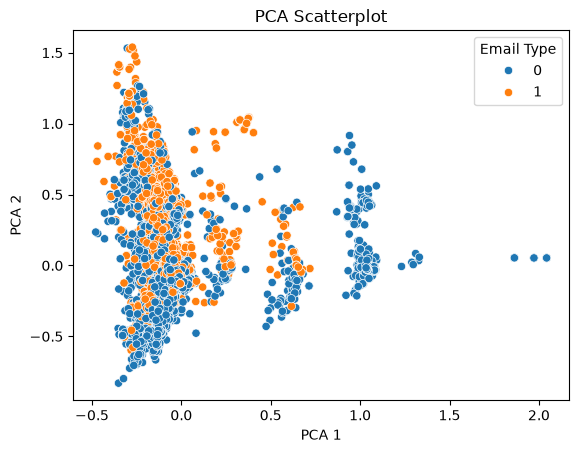

R^2 Test: 0.6613559301353326
R^2 Train: 0.7668967611277832


In [ ]:
# Question 1
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import seaborn as sns

# extract frequencies from tuples in list
freq_list = []
for each in token_freq:
    freq_list.append(each[1])

plt.hist(freq_list, bins=50)
plt.yscale("log")
plt.title("Token Occurence Histogram")
plt.xlabel("Frequency of Occurrence")
plt.ylabel("Number of Tokens")
plt.show()

# It looks like the graph has a right skew, meaning that most of the characters have low frequencies. As the token frequency increases, the number of tokens having that frequency decreases exponentially. 

# Question 2

# Load parquet
df = pd.read_parquet("data/Phishing_clean.parquet")
# Split 80/20 train-test
X = df.drop(columns=['Email Type'])
y = df["Email Type"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=65)

# Regression
sk_fit = LinearRegression().fit(X_train, y_train)

# R^2
r_squared_train = sk_fit.score(X_train, y_train)
r_squared_test = sk_fit.score(X_test, y_test)

# R^2 is 0.6571173475409766 on test and 0.7677733084118992 on train
print(f"R^2 Test: {r_squared_test}")
print(f"R^2 Train: {r_squared_train}")

# The top influential words are aging, helvetica, localized, background-image:, and thermal
coefficients = pd.Series(sk_fit.coef_, index=X.columns)
top_coefficients = coefficients.abs().sort_values(ascending=False)
print(f"Top influential words: {top_coefficients.head()}")

# Question 3

# PCA decomposition
pca = PCA(n_components=2).fit(X).transform(X)
pca_df = pd.DataFrame(pca, columns=["PC1", "PC2"])
pca_df["Email Type"] = y.values

# Scatterplot
sns.scatterplot(x="PC1", y="PC2", hue="Email Type", data=pca_df)
plt.title("PCA Scatterplot")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()

# The pattern in the scatterplot is that the scam and not scam emails overlap in the left side, of lower PCA 1 but as PCA 1 increases, not scam emails become grouped more neatly by themselves. As PCA 2 increases, more scam emails appear but they are not as neatly grouped

# Question 4

# PCA on first 2610
pca = PCA(n_components=2610)
X_train_pca = pca.fit(X_train).transform(X_train)
X_test_pca = pca.transform(X_test)

# Linear regression
pca_model = LinearRegression().fit(X_train_pca, y_train)

# R^2
r_squared_train_pca = pca_model.score(X_train_pca, y_train)
r_squared_test_pca = pca_model.score(X_test_pca, y_test)

# R^2 is 0.6613559301353326 on test and 0.7668967611277832 on train
print(f"R^2 Test: {r_squared_test_pca}")
print(f"R^2 Train: {r_squared_train_pca}")

# The model from question 2 performed about the same to the one in this question. This is because question 2 used 2711 while this one used 2610 components, which although different is still nearly same, making accuracy also almost the same.

# Question 5
# The advantage of using PCA to run high-dimensional regression is that for example in this assignment, there are many words that occur in high frequencies in emails which can make using words to identify if it is a scam hard.
# However, with PCA, it helps reduce that noise to focus on identifying if an email is a scam or not. Additionally, with this much data, PCA also helps shrink it down and make it run faster. 


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 38c56a3ecb492e1ec9cc4feee5dd351e3e5b2e71
- **AI tool and model used:** Gemini Flash-Lite

### *Prompts used

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:
```
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
```
Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.
Perform an 80/20 train-test split of the data.
Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
What words have the largest coefficients in absolute value and most strongly influence predictions? 
**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?
**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?
**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

Here is my solution:
```
# Question 1
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import seaborn as sns

# extract frequencies from tuples in list
freq_list = []
for each in token_freq:
    freq_list.append(each[1])

plt.hist(freq_list, bins=50)
plt.yscale("log")
plt.title("Token Occurence Histogram")
plt.xlabel("Frequency of Occurrence")
plt.ylabel("Number of Tokens")
plt.show()

# It looks like the graph has a right skew, meaning that most of the characters have low frequencies. As the token frequency increases, the number of tokens having that frequency decreases exponentially. 

# Question 2

# Load parquet
df = pd.read_parquet("data/Phishing_clean.parquet")
# Split 80/20 train-test
X = df.drop(columns=['Email Type'])
y = df["Email Type"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=65)

# Regression
sk_fit = LinearRegression().fit(X_train, y_train)

# R^2
r_squared_train = sk_fit.score(X_train, y_train)
r_squared_test = sk_fit.score(X_test, y_test)

# R^2 is 0.6571173475409766 on test and 0.7677733084118992 on train
print(f"R^2 Test: {r_squared_test}")
print(f"R^2 Train: {r_squared_train}")

# The top influential words are aging, helvetica, localized, background-image:, and thermal
coefficients = pd.Series(sk_fit.coef_, index=X.columns)
top_coefficients = coefficients.abs().sort_values(ascending=False)
print(f"Top influential words: {top_coefficients.head()}")

# Question 3

# PCA decomposition
pca = PCA(n_components=2).fit(X).transform(X)
pca_df = pd.DataFrame(pca, columns=["PC1", "PC2"])
pca_df["Email Type"] = y.values

# Scatterplot
sns.scatterplot(x="PC1", y="PC2", hue="Email Type", data=pca_df)
plt.title("PCA Scatterplot")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()

# The pattern in the scatterplot is that the scam and not scam emails overlap in the left side, of lower PCA 1 but as PCA 1 increases, not scam emails become grouped more neatly by themselves. As PCA 2 increases, more scam emails appear but they are not as neatly grouped

# Question 4

# PCA on first 2610
pca = PCA(n_components=2610)
X_train_pca = pca.fit(X_train).transform(X_train)
X_test_pca = pca.transform(X_test)

# Linear regression
pca_model = LinearRegression().fit(X_train_pca, y_train)

# R^2
r_squared_train_pca = pca_model.score(X_train_pca, y_train)
r_squared_test_pca = pca_model.score(X_test_pca, y_test)

# R^2 is 0.6613559301353326 on test and 0.7668967611277832 on train
print(f"R^2 Test: {r_squared_test_pca}")
print(f"R^2 Train: {r_squared_train_pca}")

# The model from question 2 performed about the same to the one in this question. This is because question 2 used 2711 while this one used 2610 components, which although different is still nearly same, making accuracy also almost the same.

# Question 5
# The advantage of using PCA to run high-dimensional regression is that for example in this assignment, there are many words that occur in high frequencies in emails which can make using words to identify if it is a scam hard.
# However, with PCA, it helps reduce that noise to focus on identifying if an email is a scam or not. Additionally, with this much data, PCA also helps shrink it down and make it run faster. 
```

Please give me any suggestions or improvements

### *AI-proposed changes


For Question 1
1. Add Context (Zipf's Law)
Suggestion: When describing the right skew and exponential drop-off in token frequencies, you can mention Zipf's Law. In natural language processing, token frequencies follow a power-law distribution where a few words appear extremely often, while the vast majority appear very rarely. Dropping this term will show a deep understanding of text data properties!

For Question 2
2. Fixing Coefficient Interpretation
The Issue: When you run coefficients.abs().sort_values(ascending=False), you successfully sort the coefficients by magnitude (absolute value), but top_coefficients.head() will display their absolute values. This means you lose the sign (+ or -), making it hard to tell whether a word increases or decreases the likelihood of an email being a scam.

The Fix: To see the actual signed coefficients for the top words, you can index back into the original coefficients series:

```
# Get the top 5 indices based on absolute value
top_indices = coefficients.abs().sort_values(ascending=False).head().index

# Print the actual signed coefficients
print("Top influential words and their signed coefficients:")
print(coefficients[top_indices])
```

For Question 4 and 5
3. Dimension Reduction Insights
Praise: Your explanation in Question 5 is spot on. Mentioning both noise reduction (discarding components with very low variance that mostly represent random noise) and computational efficiency covers the primary benefits of PCA.Bonus Context: Notice how dropping from 2,711 features down to 2,610 components barely changed the $R^2$ score at all? This tells you that the last ~100 components accounted for almost zero unique variance (likely collinear or constant columns), which is very common in one-hot-encoded text matrices.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Reject | My explanation already touches on the idea so I don't think just adding a name of a law really helps much. |
| 2 | Reject | The problem only asks for absolute value and for the biggest influencers, meaning it doesn't matter if it's positive or negative as long as it has big influence. |
| 3 | Accept | Adding an interpertation to why reducing from 2711 to 2610 didn't change accuracy would make my answer more fleshed out. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

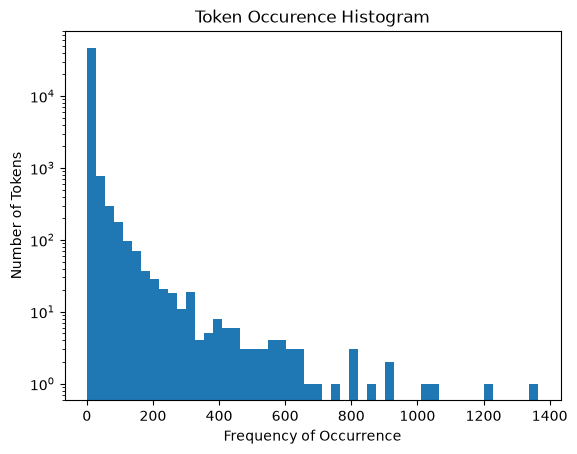

R^2 Test: 0.6571173475409766
R^2 Train: 0.7677733084118992
Top influential words: aging                0.996514
helvetica,           0.892177
localized            0.787934
background-image:    0.780070
thermal              0.671019
dtype: float64


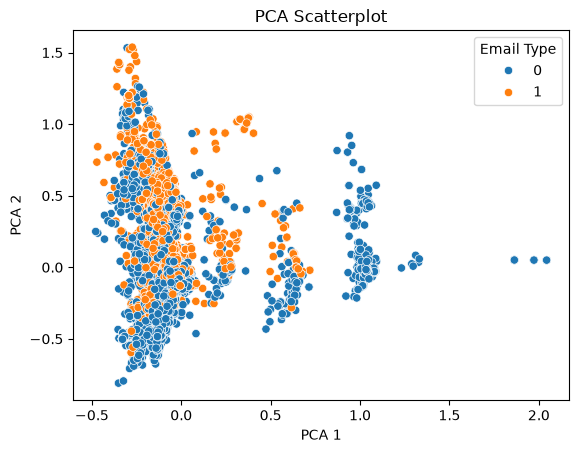

R^2 Test: 0.6613559301353326
R^2 Train: 0.7668967611277832


In [ ]:
# Your Phase 2 solution to the problem goes here.
# Question 1
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import seaborn as sns

# extract frequencies from tuples in list
freq_list = []
for each in token_freq:
    freq_list.append(each[1])

plt.hist(freq_list, bins=50)
plt.yscale("log")
plt.title("Token Occurence Histogram")
plt.xlabel("Frequency of Occurrence")
plt.ylabel("Number of Tokens")
plt.show()

# It looks like the graph has a right skew, meaning that most of the characters have low frequencies. As the token frequency increases, the number of tokens having that frequency decreases exponentially. 

# Question 2

# Load parquet
df = pd.read_parquet("data/Phishing_clean.parquet")
# Split 80/20 train-test
X = df.drop(columns=['Email Type'])
y = df["Email Type"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=65)

# Regression
sk_fit = LinearRegression().fit(X_train, y_train)

# R^2
r_squared_train = sk_fit.score(X_train, y_train)
r_squared_test = sk_fit.score(X_test, y_test)

# R^2 is 0.6571173475409766 on test and 0.7677733084118992 on train
print(f"R^2 Test: {r_squared_test}")
print(f"R^2 Train: {r_squared_train}")

# The top influential words are aging, helvetica, localized, background-image:, and thermal
coefficients = pd.Series(sk_fit.coef_, index=X.columns)
top_coefficients = coefficients.abs().sort_values(ascending=False)
print(f"Top influential words: {top_coefficients.head()}")

# Question 3

# PCA decomposition
pca = PCA(n_components=2).fit(X).transform(X)
pca_df = pd.DataFrame(pca, columns=["PC1", "PC2"])
pca_df["Email Type"] = y.values

# Scatterplot
sns.scatterplot(x="PC1", y="PC2", hue="Email Type", data=pca_df)
plt.title("PCA Scatterplot")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()

# The pattern in the scatterplot is that the scam and not scam emails overlap in the left side, of lower PCA 1 but as PCA 1 increases, not scam emails become grouped more neatly by themselves. As PCA 2 increases, more scam emails appear but they are not as neatly grouped

# Question 4

# PCA on first 2610
pca = PCA(n_components=2610)
X_train_pca = pca.fit(X_train).transform(X_train)
X_test_pca = pca.transform(X_test)

# Linear regression
pca_model = LinearRegression().fit(X_train_pca, y_train)

# R^2
r_squared_train_pca = pca_model.score(X_train_pca, y_train)
r_squared_test_pca = pca_model.score(X_test_pca, y_test)

# R^2 is 0.6613559301353326 on test and 0.7668967611277832 on train
print(f"R^2 Test: {r_squared_test_pca}")
print(f"R^2 Train: {r_squared_train_pca}")

# The model from question 2 performed about the same to the one in this question. This is because question 2 used 2711 while this one used 2610 components, which although different is still nearly same, making accuracy also almost the same.
# This means that the 100 or so components that were dropped from the 2711 to 2610 had almost no variance, meaning they were just noise that didn't contribute much, which is why dropping them did not improve nor hurt the model performance very much.

# Question 5
# The advantage of using PCA to run high-dimensional regression is that for example in this assignment, there are many words that occur in high frequencies in emails which can make using words to identify if it is a scam hard.
# However, with PCA, it helps reduce that noise to focus on identifying if an email is a scam or not. Additionally, with this much data, PCA also helps shrink it down and make it run faster. 


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]
The main improvement AI made for this assignment was to give me advice on how to make my written responses more in depth. Here, I had only touched on how the accuracy did not change because it only went from 2711 to 2610 components but didn’t give an interpretation of what the components dropped meant that would result in such a result. All the other suggestions AI gave I did not feel were very good. For example, it said that I should not include absolute values. While it is true that this would allow me to see the positive or negative influences, the question specifically asks for absolute value to just see the ones with the biggest impact, regardless of positive or negative impact. The solutions AI gave were verified by rereading the question to see if it was actually something I missed and I should fix or if AI was just suggesting something I already wrote in my answer. I have no remaining concerns.